In [22]:
import tempfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotnine as p9
import scanpy as sc
import scvi
import seaborn as sns
import torch
from scipy.stats import pearsonr

/opt/conda/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html


In [21]:
# !pip install pandas==2.0.3

  Using cached pandas-2.0.3-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (18 kB)
Using cached pandas-2.0.3-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (12.2 MB)
  Attempting uninstall: pandas
    Found existing installation: pandas 2.3.1
    Uninstalling pandas-2.3.1:
      Successfully uninstalled pandas-2.3.1


In [20]:
# !pip install mizani==0.10.0

  Attempting uninstall: mizani
    Found existing installation: mizani 0.11.3
    Uninstalling mizani-0.11.3:
      Successfully uninstalled mizani-0.11.3


In [14]:
# !pip install plotnine==0.12.0

  Using cached plotnine-0.12.0-py3-none-any.whl.metadata (8.9 kB)
  Using cached pandas-2.3.1-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (91 kB)
Using cached plotnine-0.12.0-py3-none-any.whl (1.3 MB)
Using cached pandas-2.3.1-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (12.4 MB)
  Attempting uninstall: pandas
    Found existing installation: pandas 2.0.3
    Uninstalling pandas-2.0.3:━━━━━━━━━━━━━━━━━━ 0/2 [pandas]
      Successfully uninstalled pandas-2.0.3━ 0/2 [pandas]
  Attempting uninstall: plotnine━━━━━━━━━━━━━━━━ 0/2 [pandas]
    Found existing installation: plotnine 0.13.0 0/2 [pandas]
    Uninstalling plotnine-0.13.0:━━━━━━━━━━━ 0/2 [pandas]
      Successfully uninstalled plotnine-0.13.00m 0/2 [pandas]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [plotnine]1/2 [plotnine]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency co

In [23]:
scvi.settings.seed = 0
print("Last run with scvi-tools version:", scvi.__version__)

Seed set to 0


Last run with scvi-tools version: 1.3.2


In [24]:
sc.set_figure_params(figsize=(6, 6), frameon=False)
sns.set_theme()
torch.set_float32_matmul_precision("high")
save_dir = tempfile.TemporaryDirectory()

%config InlineBackend.print_figure_kwargs={"facecolor": "w"}
%config InlineBackend.figure_format="retina"

In [25]:
adata = scvi.data.pbmcs_10x_cite_seq(save_path=save_dir.name)

INFO     Downloading file at /tmp/tmprbkw8n5j/pbmc_10k_protein_v3.h5ad                                             
Downloading...: 24938it [00:00, 114255.45it/s]                                                                                                                                                             
INFO     Downloading file at /tmp/tmprbkw8n5j/pbmc_5k_protein_v3.h5ad                                              
Downloading...: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 18295/18295.0 [00:00<00:00, 108745.42it/s]


/opt/conda/lib/python3.11/site-packages/scvi/data/_built_in_data/_cite_seq.py:47: ImplicitModificationWarning: Setting element `.obsm['protein_expression']` of view, initializing view as actual.
/opt/conda/lib/python3.11/site-packages/scvi/data/_built_in_data/_cite_seq.py:52: ImplicitModificationWarning: Setting element `.obsm['protein_expression']` of view, initializing view as actual.
/opt/conda/lib/python3.11/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.


In [26]:
# batch 0 corresponds to dataset_10k, batch 1 corresponds to dataset_5k
batch = adata.obs.batch.values.ravel()
adata.obs.batch

index
AAACCCAAGATTGTGA-1    PBMC10k
AAACCCACATCGGTTA-1    PBMC10k
AAACCCAGTACCGCGT-1    PBMC10k
AAACCCAGTATCGAAA-1    PBMC10k
AAACCCAGTCGTCATA-1    PBMC10k
                       ...   
TTTGGTTGTACGAGTG-1     PBMC5k
TTTGTTGAGTTAACAG-1     PBMC5k
TTTGTTGCAGCACAAG-1     PBMC5k
TTTGTTGCAGTCTTCC-1     PBMC5k
TTTGTTGCATTGCCGG-1     PBMC5k
Name: batch, Length: 10849, dtype: object

In [27]:
held_out_proteins = adata.obsm["protein_expression"][batch == "PBMC5k"].copy()
adata.obsm["protein_expression"].loc[batch == "PBMC5k"] = np.zeros_like(
    adata.obsm["protein_expression"][batch == "PBMC5k"]
)

In [28]:
sc.pp.highly_variable_genes(
    adata, batch_key="batch", flavor="seurat_v3", n_top_genes=4000, subset=True
)

/opt/conda/lib/python3.11/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.


In [29]:
scvi.model.TOTALVI.setup_anndata(
    adata, batch_key="batch", protein_expression_obsm_key="protein_expression"
)

INFO     Using column names from columns of adata.obsm['protein_expression']                                       
INFO     Found batches with missing protein expression                                                             


/tmp/ipykernel_3316/1447945926.py:1: DeprecationWarning: We recommend using setup_mudata for multi-modal data.It does not influence model performance


In [30]:
model = scvi.model.TOTALVI(adata, latent_distribution="normal", n_layers_decoder=2)


INFO     Computing empirical prior initialization for protein background.                                          


/tmp/ipykernel_3316/1389761034.py:1: UserWarning: Some proteins have all 0 counts in some batches. These proteins will be treated as missing measurements; however, this can occur due to experimental design/biology. Reinitialize the model with `override_missing_proteins=True`,to override this behavior.


In [31]:
model.train()


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/opt/conda/lib/python3.11/site-packages/lightning/pytorch/core/optimizer.py:317: The lr scheduler dict contains the key(s) ['monitor'], but the keys will be ignored. You need to call `lr_scheduler.step()` manually in manual optimization.
/opt/conda/lib/python3.11/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:425: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=39` in the `DataLoader` to improve performance.
/opt/conda/lib/python3.11/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:425: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=39` in the `DataLoader` to improve performance.


Epoch 293/400:  73%|█████████████████████████████████████████████████████████████████▉                        | 293/400 [15:15<05:34,  3.13s/it, v_num=1, train_loss_step=1.14e+3, train_loss_epoch=1.2e+3]
Monitored metric elbo_validation did not improve in the last 45 records. Best score: 1220.496. Signaling Trainer to stop.


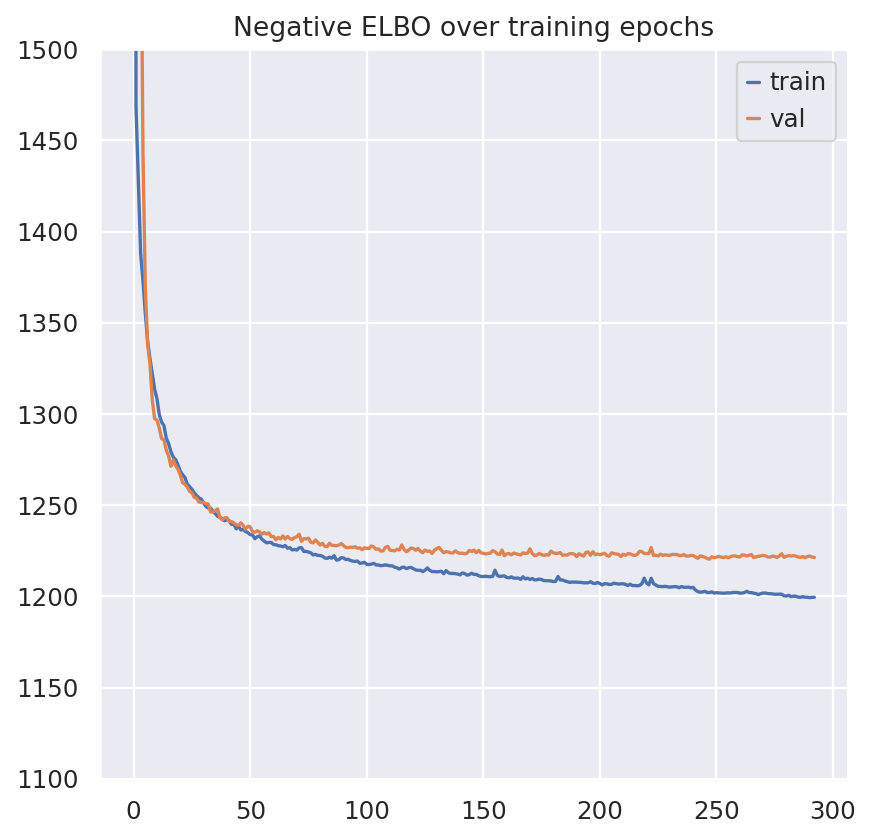

In [32]:
plt.plot(model.history["elbo_train"], label="train")
plt.plot(model.history["elbo_validation"], label="val")
plt.title("Negative ELBO over training epochs")
plt.ylim(1100, 1500)
plt.legend()

In [33]:
TOTALVI_LATENT_KEY = "X_totalVI"
PROTEIN_FG_KEY = "protein_fg_prob"

adata.obsm[TOTALVI_LATENT_KEY] = model.get_latent_representation()
adata.obsm[PROTEIN_FG_KEY] = model.get_protein_foreground_probability(transform_batch="PBMC10k")

rna, protein = model.get_normalized_expression(
    transform_batch="PBMC10k", n_samples=25, return_mean=True
)

In [34]:
protein.iloc[:5, :5]

,CD3_TotalSeqB,CD4_TotalSeqB,CD8a_TotalSeqB,CD14_TotalSeqB,CD15_TotalSeqB
index,,,,,
AAACCCAAGATTGTGA-1,42.437714,696.073914,12.899115,2727.280029,278.116882
AAACCCACATCGGTTA-1,68.072296,477.668060,5.187573,1929.941528,264.472687
AAACCCAGTACCGCGT-1,37.722843,1058.340454,14.964363,3723.848633,330.672882
AAACCCAGTATCGAAA-1,6.420334,3.710185,64.294655,0.968526,359.098999
AAACCCAGTCGTCATA-1,3.303757,0.051366,206.658707,0.041516,256.268829


In [35]:
_, protein_means = model.get_normalized_expression(
    n_samples=25,
    transform_batch="PBMC10k",
    include_protein_background=True,
    sample_protein_mixing=False,
    return_mean=True,
)

In [36]:
TOTALVI_CLUSTERS_KEY = "leiden_totalVI"

sc.pp.neighbors(adata, use_rep=TOTALVI_LATENT_KEY)
sc.tl.umap(adata, min_dist=0.4)
sc.tl.leiden(adata, key_added=TOTALVI_CLUSTERS_KEY)

/opt/conda/lib/python3.11/site-packages/numba/np/ufunc/parallel.py:371: NumbaWarning: The TBB threading layer requires TBB version 2021 update 6 or later i.e., TBB_INTERFACE_VERSION >= 12060. Found TBB_INTERFACE_VERSION = 12050. The TBB threading layer is disabled.
/tmp/ipykernel_3316/681923621.py:5: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.


/opt/conda/lib/python3.11/site-packages/anndata/_core/anndata.py:1138: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
/opt/conda/lib/python3.11/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.


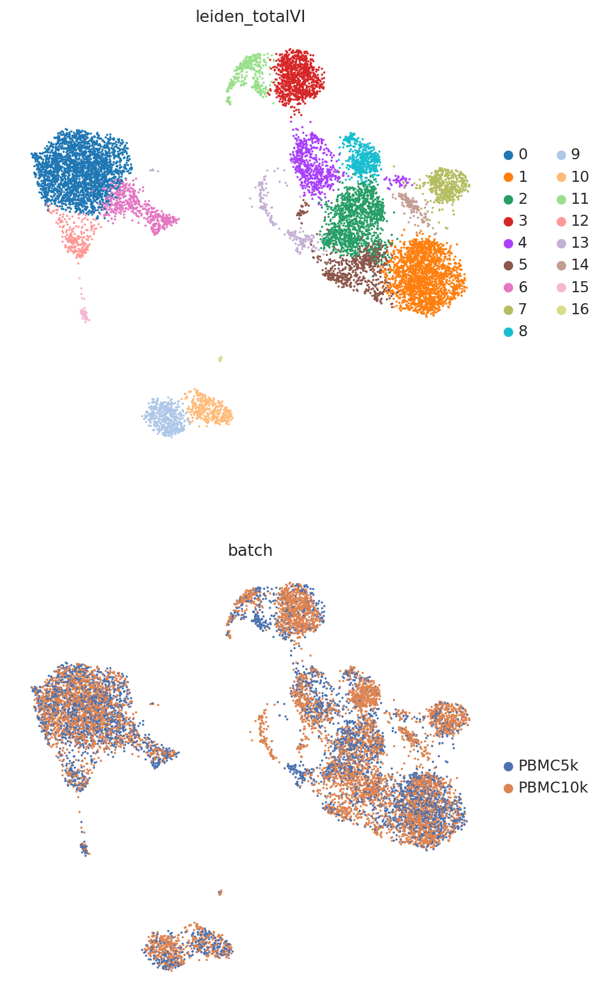

In [37]:
perm_inds = np.random.permutation(len(adata))
sc.pl.umap(
    adata[perm_inds],
    color=[TOTALVI_CLUSTERS_KEY, "batch"],
    ncols=1,
    frameon=False,
)

In [38]:
batch = adata.obs.batch.values.ravel()
combined_protein = np.concatenate(
    [adata.obsm["protein_expression"].values[batch == "PBMC10k"], held_out_proteins],
    axis=0,
)

# cleaner protein names
parsed_protein_names = [p.split("_")[0] for p in adata.obsm["protein_expression"].columns]
for i, p in enumerate(parsed_protein_names):
    adata.obs[f"{p} imputed"] = protein_means.iloc[:, i]
    adata.obs[f"{p} observed"] = combined_protein[:, i]

/opt/conda/lib/python3.11/site-packages/anndata/_core/anndata.py:1138: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.





In [39]:
viz_keys = []
for p in parsed_protein_names:
    viz_keys.append(p + " imputed")
    viz_keys.append(p + " observed")

sc.pl.umap(
    adata[adata.obs.batch == "PBMC5k"],
    color=viz_keys,
    ncols=2,
    vmax="p99",
    frameon=False,
    add_outline=True,
    wspace=0.1,
)

# Imputed vs denoised correlations

In [40]:
imputed_pros = protein_means[batch == "PBMC5k"]
held_vs_denoised = pd.DataFrame()
held_vs_denoised["Observed (log)"] = np.log1p(held_out_proteins.values.ravel())
held_vs_denoised["Imputed (log)"] = np.log1p(imputed_pros.to_numpy().ravel())
protein_names_corrs = []
for i in range(len(parsed_protein_names)):
    protein_names_corrs.append(
        parsed_protein_names[i]
        + ": Corr="
        + str(np.round(pearsonr(held_out_proteins.values[:, i], imputed_pros.iloc[:, i])[0], 3))
    )
held_vs_denoised["Protein"] = protein_names_corrs * len(held_out_proteins)
held_vs_denoised.head()

,Observed (log),Imputed (log),Protein
0,3.258097,4.459713,CD3: Corr=0.783
1,5.105945,6.931191,CD4: Corr=0.846
2,2.833213,4.391757,CD8a: Corr=0.783
3,6.546785,8.173656,CD14: Corr=0.91
4,2.995732,5.780170,CD15: Corr=0.064


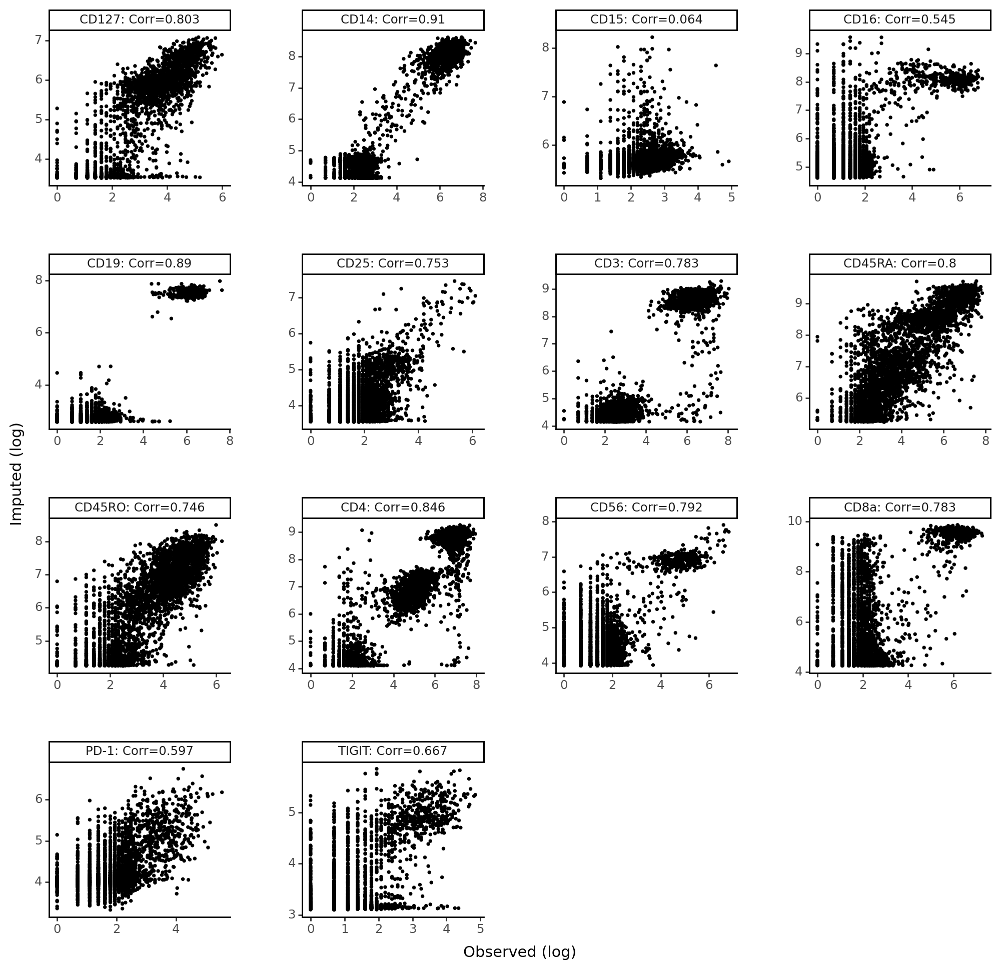

<Figure Size: (1000 x 1000)>

In [41]:
p9.theme_set(p9.theme_classic)
(
    p9.ggplot(held_vs_denoised, p9.aes("Observed (log)", "Imputed (log)"))
    + p9.geom_point(size=0.5)
    + p9.facet_wrap("~Protein", scales="free")
    + p9.theme(
        figure_size=(10, 10),
        panel_spacing=0.05,
    )
)